# Member 1 - FT-Transformer: combined development notebook

This notebook starts with the full earlier FT-Transformer workflow, followed by the completed strict nested evaluation. All code from both notebooks remains in executable code cells, and the saved outputs are retained.

**Reading the results:** the first workflow documents the earlier fixed-candidate and controlled-screening experiments. Its references to a final run describe that historical stage. The appended eight-candidate nested evaluation supplies the current formal group results at `results/models/ft_transformer/strict_nested/oof_predictions.csv`.

**Execution:** Run All reviews saved results without training or exporting artifacts. Set `RUN_HISTORICAL_TRAINING=True` in setup to repeat the weighted FT02 experiment with the current adapter; each repetition writes to a unique directory under `results/models/ft_transformer/reruns/`. This is a new experiment, not an exact reproduction of the older checkpoint-restoration implementation. The appended formal section uses its separate `RUN_TRAINING=False` flag. All 18 code cells remain executable.


# FT-Transformer — Employee Resignation Prediction

**Member 1 model:** FT-Transformer  
**Task:** Binary classification  
**Target:** `Resigned` (`1` = resigned)  
**Primary metric:** Average Precision / PR-AUC

## Objective

Evaluate FT-Transformer on the project's **80,000-row development partition** using the frozen **5-fold cross-validation** registry and all **17 approved predictors**.

The **20,000-row formal holdout remains locked**. It is excluded from preprocessing, class-weight calculation, inner validation, early stopping, hyperparameter screening, model selection, threshold analysis, and OOF evaluation.

**Final development status:** weighted FT-Transformer with leakage-safe inner validation, PR-AUC early stopping, controlled hyperparameter screening, and complete 80,000-row OOF evaluation.


## Development isolation and current repetition protocol

Each outer round excludes 16,000 development validation rows from its 64,000 training rows. A stratified 15% inner split selects an epoch count using Average Precision. Numerical standardization, category mappings and positive-class weighting are fitted only on inner-training rows. Unknown/missing categorical values map to index 0.

For a deliberate FT02 repetition with the **current adapter**, candidate training uses weighted BCE, AdamW, inner AP early stopping and ReduceLROnPlateau. A **fresh model** then trains on the 54,400 inner-training rows for the selected epoch count, with no final-fit learning-rate scheduler (`refit_outer_train=False`). Selection weights are not restored for predictions. This differs from the older implementation's recorded checkpoint-restoration claims.

The saved-review path reports the original historical predictions without claiming to reproduce them. The shared runner rejects formal-holdout IDs, and the development loader skips holdout predictors/labels before parsing them. Employee_ID, Hire_Date and Resigned are never predictors. At approximately 10.01% positive prevalence, accuracy alone is unsuitable; FT02 uses the inner-training negative/positive ratio for class weighting, while AP and ROC-AUC assess ranking.


In [19]:
# -----------------------------
# 1. Imports and project setup
# -----------------------------

import json
import sys
import time

RUN_HISTORICAL_TRAINING = False
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from sklearn.metrics import precision_recall_curve

# Resolve the repository root from notebooks/team_contributions/models/member_1_ft_transformer/.
def find_project_root(start_path: Path | None = None) -> Path:
    """Locate the repository root from any notebook launch directory."""
    start = (start_path or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "feature_contract.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate repository root containing configs/feature_contract.yaml")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.metrics import calculate_binary_metrics
from src.models.ft_transformer import FTTransformerAdapter
from src.models.runner import run_5fold_cv
from src.models.base import OOFResult
from src.models.experiment_outputs import create_run_directory
from src.evaluation.inputs import load_development_data
from src.evaluation.oof_validation import validate_oof_predictions

pd.set_option("display.max_columns", None)

CONFIG_PATH = PROJECT_ROOT / "configs" / "models" / "ft_transformer.yaml"
FEATURE_CONTRACT_PATH = PROJECT_ROOT / "configs" / "feature_contract.yaml"
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Extended_Employee_Performance_and_Productivity_Data.csv"
SPLIT_PATH = PROJECT_ROOT / "data" / "processed" / "split_registry.csv"
RESULTS_DIR = PROJECT_ROOT / "results" / "models" / "ft_transformer"
HISTORICAL_RESULTS_DIR = RESULTS_DIR / "weighted_early_stopping_final"

required_paths = [CONFIG_PATH, FEATURE_CONTRACT_PATH, DATA_PATH, SPLIT_PATH]
missing_paths = [str(path) for path in required_paths if not path.exists()]
assert not missing_paths, f"Missing required project files: {missing_paths}"

print("Project root:", PROJECT_ROOT)
print("Results directory:", RESULTS_DIR)


Project root: D:\Employee_Resignation_Prediction
Results directory: D:\Employee_Resignation_Prediction\results\models\ft_transformer


In [20]:
# 2. Load canonical configuration and define the retained historical run parameters
with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    ft_config = yaml.safe_load(file)
with open(FEATURE_CONTRACT_PATH, "r", encoding="utf-8") as file:
    feature_contract = yaml.safe_load(file)

model_name = ft_config["model"]["name"]
model_id = ft_config["model"]["model_id"]
fixed_params = ft_config["fixed_params"].copy()
# The current config uses an explicit candidate registry rather than a legacy search_space block.
# FT02 supplies the weighted architecture for deliberate new repetitions.
# Historical saved results retain their original configuration and protocol metadata.
ft02 = next(c for c in ft_config["candidates"] if c["id"] == "FT02")
final_run_params = {**fixed_params, **ft02["params"], "validation_fraction_inner": ft_config["inner_validation"]["fraction"], "max_epochs": ft_config["inner_validation"]["max_epochs"], "patience": ft_config["inner_validation"]["patience"], "seed": ft_config["reproducibility"]["seed"]}
config_summary = pd.DataFrame([(k,v) for k,v in final_run_params.items()], columns=["Setting","Value"])
display(config_summary)
print("Canonical candidate registry:", [c["id"] for c in ft_config["candidates"]])
assert final_run_params["weighting"] == "dynamic_ratio"


,Setting,Value
0,optimizer,AdamW
1,weighting,dynamic_ratio
2,weight_decay,0.00001
3,attention_dropout,0.1
4,residual_dropout,0.0
5,batch_size,512
6,seed,42
7,max_epochs,100
8,patience,15
9,lr_scheduler,ReduceLROnPlateau


Canonical candidate registry: ['FT01', 'FT02', 'FT03', 'FT04', 'FT05', 'FT06', 'FT07', 'FT08']


In [21]:
# -----------------------------
# 3. Reproducibility and compute environment
# -----------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device_label = (
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
)

print("Python kernel:", sys.executable)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Training device:", device_label)

if torch.cuda.is_available():
    print("PyTorch CUDA runtime:", torch.version.cuda)
    print(
        "GPU memory:",
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB",
    )

print("Random seed:", fixed_params["seed"])


Python kernel: c:\Python314\python.exe
PyTorch version: 2.13.0+cu130
CUDA available: True
Training device: NVIDIA GeForce RTX 4060 Laptop GPU
PyTorch CUDA runtime: 13.0
GPU memory: 8.00 GB
Random seed: 42


In [22]:
# 4. Read only frozen development predictors/labels; inspect holdout IDs only.
development_data, split_registry = load_development_data(PROJECT_ROOT)
assert development_data.shape == (80_000, 20)
assert split_registry.shape == (100_000, 3)
print("Development data shape:", development_data.shape)
print("Split registry shape:", split_registry.shape)
print("Partition counts:")
print(split_registry["partition"].value_counts())


Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).
Development data shape: (80000, 20)
Split registry shape: (100000, 3)
Partition counts:
partition
development    80000
holdout        20000
Name: count, dtype: int64


In [23]:
# -----------------------------
# 5. Isolate the development partition and enforce holdout protection
# -----------------------------

development_ids = set(
    split_registry.loc[
        split_registry["partition"] == "development",
        "Employee_ID",
    ]
)
holdout_ids = set(
    split_registry.loc[
        split_registry["partition"] == "holdout",
        "Employee_ID",
    ]
)

# Development filtering and shape/prevalence logging were performed by the loader.
development_df = development_data.merge(
    split_registry[["Employee_ID", "partition", "cv_fold"]],
    on="Employee_ID",
    how="left",
    validate="one_to_one",
)
development_df["cv_fold"] = development_df["cv_fold"].astype(int)

assert len(development_data) == 80_000
assert "cv_fold" not in development_data.columns
assert "partition" not in development_data.columns
assert len(holdout_ids) == 20_000
assert set(development_data["Employee_ID"]).isdisjoint(holdout_ids)
assert set(development_df["cv_fold"].unique()) == {1, 2, 3, 4, 5}
assert development_df["cv_fold"].value_counts().eq(16_000).all()

print("Development rows:", len(development_data))
print("Formal holdout rows excluded:", len(holdout_ids))
print("Holdout IDs present in modeling data: 0")
print("\nDevelopment fold counts:")
print(development_df["cv_fold"].value_counts().sort_index())


Development rows: 80000
Formal holdout rows excluded: 20000
Holdout IDs present in modeling data: 0

Development fold counts:
cv_fold
1    16000
2    16000
3    16000
4    16000
5    16000
Name: count, dtype: int64


In [24]:
# -----------------------------
# 6. Validate the feature contract and build X / y
# -----------------------------

numerical_features = feature_contract["numerical_features"]
categorical_features = feature_contract["categorical_features"]
primary_model_features = feature_contract["primary_model_features"]
target_config = feature_contract["target"]

numerical_feature_names = [item["name"] for item in numerical_features]
categorical_feature_names = [item["name"] for item in categorical_features]
target_column = target_config["column"]

assert len(numerical_feature_names) == 13
assert len(categorical_feature_names) == 4
assert len(primary_model_features) == 17
assert set(numerical_feature_names + categorical_feature_names) == set(primary_model_features)

required_columns = primary_model_features + [target_column, "Employee_ID", "cv_fold"]
missing_columns = [c for c in required_columns if c not in development_df.columns]
assert not missing_columns, f"Missing required columns: {missing_columns}"

X = development_df[primary_model_features].copy()
y = development_df[target_column].astype(int).copy()
employee_ids = development_df["Employee_ID"].copy()
cv_folds = development_df["cv_fold"].copy()

assert X.shape == (80_000, 17)
assert len(y) == 80_000
assert set(y.unique()) == {0, 1}
assert X.isna().sum().sum() == 0
assert "Employee_ID" not in X.columns
assert "Hire_Date" not in X.columns
assert target_column not in X.columns

print("Predictor matrix:", X.shape)
print("Numerical / ordinal predictors:", len(numerical_feature_names))
print("Categorical predictors:", len(categorical_feature_names))
print("Missing predictor values:", int(X.isna().sum().sum()))
print("Development resignation prevalence:", f"{y.mean():.4%}")


Predictor matrix: (80000, 17)
Numerical / ordinal predictors: 13
Categorical predictors: 4
Missing predictor values: 0
Development resignation prevalence: 10.0100%


In [25]:
# -----------------------------
# 7. Verify fold balance
# -----------------------------

fold_summary = (
    development_df
    .groupby("cv_fold")[target_column]
    .agg(
        total_rows="size",
        resigned_count="sum",
        resignation_rate="mean",
    )
    .reset_index()
)

fold_summary["not_resigned_count"] = (
    fold_summary["total_rows"] - fold_summary["resigned_count"]
)
fold_summary["resignation_rate_pct"] = (
    fold_summary["resignation_rate"] * 100
).round(3)

fold_summary = fold_summary[
    [
        "cv_fold",
        "total_rows",
        "not_resigned_count",
        "resigned_count",
        "resignation_rate_pct",
    ]
]

assert len(fold_summary) == 5
assert (fold_summary["total_rows"] == 16_000).all()
assert (fold_summary["resigned_count"] > 0).all()
assert (fold_summary["not_resigned_count"] > 0).all()

display(fold_summary)


,cv_fold,total_rows,not_resigned_count,resigned_count,resignation_rate_pct
0,1,16000,14399,1601,10.006
1,2,16000,14399,1601,10.006
2,3,16000,14398,1602,10.013
3,4,16000,14398,1602,10.013
4,5,16000,14398,1602,10.013


In [26]:
# -----------------------------
# 8. Verify categorical coverage across outer folds
# -----------------------------

coverage_records = []

for fold in sorted(development_df["cv_fold"].unique()):
    train_fold_df = development_df[development_df["cv_fold"] != fold]
    val_fold_df = development_df[development_df["cv_fold"] == fold]

    for feature in categorical_feature_names:
        train_categories = set(train_fold_df[feature].dropna().unique())
        validation_categories = set(val_fold_df[feature].dropna().unique())
        unseen = validation_categories - train_categories

        coverage_records.append(
            {
                "cv_fold": fold,
                "feature": feature,
                "train_categories": len(train_categories),
                "validation_categories": len(validation_categories),
                "unseen_categories": len(unseen),
            }
        )

categorical_coverage = pd.DataFrame(coverage_records)
total_unseen = int(categorical_coverage["unseen_categories"].sum())

assert total_unseen == 0, (
    "At least one outer-validation fold contains a category absent "
    "from its corresponding training folds."
)

display(categorical_coverage)
print("\nTotal unseen validation categories:", total_unseen)


,cv_fold,feature,train_categories,validation_categories,unseen_categories
0,1,Department,9,9,0
1,1,Gender,3,3,0
2,1,Job_Title,7,7,0
3,1,Education_Level,4,4,0
4,2,Department,9,9,0
5,2,Gender,3,3,0
6,2,Job_Title,7,7,0
7,2,Education_Level,4,4,0
8,3,Department,9,9,0
9,3,Gender,3,3,0



Total unseen validation categories: 0


## Development History, Class Weighting, and Threshold Findings

Three main FT-Transformer development experiments were completed.

| Experiment | PR-AUC | ROC-AUC | F1 @ 0.50 | Brier | Main observation |
|---|---:|---:|---:|---:|---|
| Unweighted fixed baseline | 10.11% | 49.88% | 0.00% | 0.0907 | The default threshold produced effectively no positive predictions; ranking remained no-skill. |
| Weighted fixed baseline | 9.88% | 49.57% | 16.64% | 0.2515 | Weighting increased sensitivity to resignation, but did not improve ranking. |
| Weighted + early-stopping final | **10.00%** | **49.73%** | **16.73%** | **0.2474** | More controlled training, but discrimination remained approximately no-skill. |

Development resignation prevalence is approximately **10.01%**, so PR-AUC near 10% is approximately the no-skill reference.

### Why class weighting was introduced

The unweighted baseline produced an F1 of zero at threshold 0.50. To address class imbalance, the adapter was updated to calculate:

`pos_weight = negative_count / positive_count`

from the training data available inside the fold. In the final adapter, this is calculated from the **inner-training target only**.

### Threshold analysis

Threshold analysis on the **weighted fixed baseline OOF predictions** found a numerically highest F1 near threshold `0.05`, but that operating point predicted **every development employee as positive**:

- Precision ≈ 10.01%
- Recall = 100%
- F1 ≈ 18.20%
- Balanced accuracy = 50%
- Predicted-positive rate = 100%

That was a trivial all-positive classifier, so threshold adjustment was not adopted as a solution.


## Controlled Hyperparameter Screening

Hyperparameter screening used only the outer Fold 1 **training partition** and its internal validation split. The untouched Fold 1 outer-validation data was not used to choose hyperparameters.

Where a single-seed result suggested a potentially meaningful change, the strongest candidates were checked across seeds `42`, `123`, and `2026`.

| Parameter | Candidates examined | Retained value | Selection evidence |
|---|---|---:|---|
| Learning rate | 0.0001, 0.0003, 0.001 | **0.001** | Best multi-seed mean inner PR-AUC: 10.66% |
| `d_block` | 32, 64, 128 | **64** | Highest seed-42 inner PR-AUC: 10.76% |
| `n_blocks` | 2, 3, 4 | **3** | Best multi-seed mean inner PR-AUC: 10.66% |
| `ffn_d_hidden` | 64, 128, 256 | **128** | Best multi-seed mean inner PR-AUC: 10.66% |
| Attention heads | 2, 4, 8 | **4** | Highest seed-42 inner PR-AUC: 10.76% |
| FFN dropout | 0.0, 0.1, 0.2 | **0.1** | Highest seed-42 inner PR-AUC: 10.76% |

The apparent single-seed advantages from two Transformer blocks and FFN hidden size 64 did not remain superior across multiple seeds. The controlled search therefore returned to the original architecture.

Further FT-Transformer tuning was stopped to avoid overfitting the development process to validation noise.


## Executing or reviewing the earlier weighted experiment

The setup flag `RUN_HISTORICAL_TRAINING=False` loads the preserved historical OOF predictions, fold metrics and summary. Their IDs, frozen folds, source targets and probabilities are validated. Missing or invalid evidence raises an error. Original metadata is retained as historical claims; missing per-fold diagnostics are not reconstructed.

Set the flag to `True` to run **FT02**, explicitly weighted with `dynamic_ratio`. The current adapter selects epochs on the inner split and fits fresh weights on inner-training rows. Each repetition receives a unique output directory under `results/models/ft_transformer/reruns/`; saved historical and formal artifacts are preserved. Measured training metadata is exported from all five fitted adapters.

The appended formal search differs: it tunes FT01–FT08 inside each outer fold and refits the selected winner on all 64,000 outer-training rows. Only that strict nested result is the current group input.


In [27]:
# -----------------------------
# 9. Create a fresh final adapter factory
# -----------------------------

def make_final_ft_transformer():
    # Return a new unfitted adapter for each outer CV fold.
    return FTTransformerAdapter(
        name=model_name,
        model_id=model_id,
        params=final_run_params.copy(),
        candidate_id="FT02",
        refit_outer_train=False,
        categorical_features=categorical_feature_names.copy(),
    )

adapter_a = make_final_ft_transformer()
adapter_b = make_final_ft_transformer()

assert adapter_a is not adapter_b
assert adapter_a.params is not adapter_b.params
assert adapter_a.categorical_features is not adapter_b.categorical_features
assert not adapter_a.get_metadata()["fitted"]
assert not adapter_b.get_metadata()["fitted"]

print("Final adapter factory validation passed.")
print("Model:", adapter_a.name)

assert adapter_a.params["weighting"] == "dynamic_ratio"
assert not adapter_a.refit_outer_train


Final adapter factory validation passed.
Model: FT-Transformer


In [28]:
if RUN_HISTORICAL_TRAINING:
    # -----------------------------
    # 10. Final weighted + early-stopping 5-fold OOF experiment
    # -----------------------------

    print("New weighted FT02 development repetition (current adapter)")
    print("-------------------------------------------------")
    print("Development rows:", len(development_data))
    print("Formal holdout rows used: 0")
    print("Predictors:", len(primary_model_features))
    print("Outer folds: 5")
    print("Maximum epochs:", final_run_params["max_epochs"])
    print("Early-stopping patience:", final_run_params["patience"])
    print(
        "Inner validation fraction:",
        final_run_params["validation_fraction_inner"],
    )
    print("Primary early-stopping metric: PR-AUC")
    print("Class weighting: inner-training positive-class weight")
    print("Device:", device_label)

    FINAL_ES_DIR = create_run_directory(PROJECT_ROOT, "ft_transformer")
    final_cv_start = time.perf_counter()

    final_ft_cv_result = run_5fold_cv(
        adapter_factory=make_final_ft_transformer,

        # IMPORTANT:
        # Raw development rows only. The runner attaches split columns
        # from split_registry and protects the formal holdout.
        data=development_data,

        split_registry=split_registry,
        feature_cols=primary_model_features,
        target_col=target_column,
        id_col="Employee_ID",
        fold_col="cv_fold",
        partition_col="partition",
        development_label="development",
        holdout_label="holdout",
        expected_folds=(1, 2, 3, 4, 5),
        expected_model_name=model_name,
    )

    final_cv_elapsed = time.perf_counter() - final_cv_start

    assert len(final_ft_cv_result.predictions) == 80_000
    assert final_ft_cv_result.predictions["Employee_ID"].is_unique
    assert set(final_ft_cv_result.predictions["cv_fold"].unique()) == {1, 2, 3, 4, 5}
    assert set(final_ft_cv_result.predictions["Employee_ID"]).isdisjoint(holdout_ids)

    print("\nFinal 5-fold FT-Transformer run completed.")
    print("Elapsed time:", f"{final_cv_elapsed / 60:.2f} minutes")
    print("OOF prediction rows:", len(final_ft_cv_result.predictions))

else:
    FINAL_ES_DIR = HISTORICAL_RESULTS_DIR
    saved_predictions = pd.read_csv(FINAL_ES_DIR / "ft_transformer_final_oof_predictions.csv")
    saved_folds = pd.read_csv(FINAL_ES_DIR / "ft_transformer_final_fold_metrics.csv")
    saved_summary = json.loads((FINAL_ES_DIR / "ft_transformer_final_summary_metrics.json").read_text(encoding="utf-8"))
    saved_metadata = json.loads((FINAL_ES_DIR / "ft_transformer_final_run_metadata.json").read_text(encoding="utf-8"))
    saved_configuration = json.loads((FINAL_ES_DIR / "ft_transformer_final_configuration.json").read_text(encoding="utf-8"))
    validate_oof_predictions(saved_predictions, split_registry, source_data=development_data, expected_model_name=model_name)
    final_ft_cv_result = OOFResult(
        model_name=model_name, model_id=model_id,
        predictions=saved_predictions, fold_metrics=saved_folds,
        summary_metrics=saved_summary,
        fit_time_seconds_total=float(saved_summary["total_fit_time_seconds"]),
        predict_time_seconds_total=float(saved_summary["total_predict_time_seconds"]),
        metadata={"saved_historical_metadata": saved_metadata, "saved_historical_configuration": saved_configuration,
                  "protocol_status": "original metadata claims; per-fold adapter diagnostics unavailable"},
    )
    final_cv_elapsed = float(saved_metadata["elapsed_minutes"]) * 60
    print("Loaded and validated historical evidence; no training or artifact export.")
    print("Saved protocol metadata is historical, not measured current-adapter diagnostics.")


Loaded and validated historical evidence; no training or artifact export.
Saved protocol metadata is historical, not measured current-adapter diagnostics.


### Preserved historical development run (not a new repetition)

The completed final run used an **NVIDIA GeForce RTX 4060 Laptop GPU** and finished in approximately **6.20 minutes** according to its saved run metadata.

| Metric | Recorded value |
|---|---:|
| Pooled PR-AUC / Average Precision | **0.099979** |
| Pooled ROC-AUC | **0.497254** |
| Pooled F1 @ 0.50 | **0.167258** |
| Pooled Brier score | **0.247413** |
| CV mean PR-AUC | **0.099696** |
| CV SD PR-AUC | **0.002237** |
| CV mean ROC-AUC | **0.497570** |
| CV SD ROC-AUC | **0.006597** |
| Total fit time | **370.72 s** |
| Total prediction time | **1.19 s** |

The run produced one OOF prediction for each of the **80,000 development employees** and used **zero formal-holdout rows**.

These numbers describe the preserved historical run. If retraining is enabled, use the computed tables below for the new repetition rather than this historical table.


In [29]:
# -----------------------------
# 11. Fold-level and pooled OOF performance
# -----------------------------

fold_metrics = final_ft_cv_result.fold_metrics.copy()
oof_predictions = final_ft_cv_result.predictions.copy()

expected_metric_columns = {
    "fold",
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "brier_score",
    "fit_time_seconds",
    "predict_time_seconds",
}

missing_metric_columns = expected_metric_columns - set(fold_metrics.columns)
assert not missing_metric_columns, (
    f"Fold metrics are missing columns: {sorted(missing_metric_columns)}"
)
assert len(fold_metrics) == 5

display(
    fold_metrics[
        [
            "fold",
            "average_precision",
            "roc_auc",
            "brier_score",
            "balanced_accuracy",
            "precision",
            "recall",
            "f1",
            "predicted_positive_rate",
            "fit_time_seconds",
            "predict_time_seconds",
        ]
    ].round(6)
)

pooled_metrics = calculate_binary_metrics(
    y_true=oof_predictions["y_true"],
    y_probability=oof_predictions["y_probability"],
    y_pred=oof_predictions["y_pred_0_5"],
    threshold=0.50,
)

prevalence = float(oof_predictions["y_true"].mean())
no_skill_ap = prevalence
constant_prevalence_brier = prevalence * (1.0 - prevalence)

metric_summary = pd.DataFrame(
    [
        ("Average Precision / PR-AUC", pooled_metrics["average_precision"]),
        ("No-skill AP (prevalence)", no_skill_ap),
        ("ROC-AUC", pooled_metrics["roc_auc"]),
        ("Brier score", pooled_metrics["brier_score"]),
        ("Constant-prevalence Brier reference", constant_prevalence_brier),
        ("Balanced accuracy @ 0.50", pooled_metrics["balanced_accuracy"]),
        ("Precision @ 0.50", pooled_metrics["precision"]),
        ("Recall @ 0.50", pooled_metrics["recall"]),
        ("F1 @ 0.50", pooled_metrics["f1"]),
        (
            "Predicted-positive rate @ 0.50",
            pooled_metrics["predicted_positive_rate"],
        ),
    ],
    columns=["Metric", "Value"],
)

print("\nPooled OOF metrics")
display(metric_summary.round(6))

print(
    "PR-AUC lift over prevalence:",
    f"{pooled_metrics['average_precision'] - no_skill_ap:+.6f}",
)


,fold,average_precision,roc_auc,brier_score,balanced_accuracy,precision,recall,f1,predicted_positive_rate,fit_time_seconds,predict_time_seconds
0,1,0.096579,0.485936,0.242199,0.491374,0.095721,0.342286,0.149604,0.357812,93.375514,0.223572
1,2,0.102827,0.501306,0.255291,0.502728,0.100974,0.544035,0.170333,0.539125,156.767362,0.214821
2,3,0.100136,0.500504,0.217159,0.500000,0.000000,0.000000,0.000000,0.000000,44.011174,0.244908
3,4,0.099155,0.498664,0.261640,0.498523,0.099760,0.726592,0.175433,0.729250,44.829481,0.267360
4,5,0.099781,0.501442,0.260776,0.501856,0.100468,0.978152,0.182220,0.974812,31.731506,0.244332



Pooled OOF metrics


,Metric,Value
0,Average Precision / PR-AUC,0.099979
1,No-skill AP (prevalence),0.100100
2,ROC-AUC,0.497254
3,Brier score,0.247413
4,Constant-prevalence Brier reference,0.090080
5,Balanced accuracy @ 0.50,0.498906
6,Precision @ 0.50,0.099721
7,Recall @ 0.50,0.518232
8,F1 @ 0.50,0.167258
9,Predicted-positive rate @ 0.50,0.520200


PR-AUC lift over prevalence: -0.000121


,Statistic,Probability
0,Minimum,0.159644
1,1st percentile,0.332647
2,25th percentile,0.464220
3,Median,0.502251
4,Mean,0.493553
5,75th percentile,0.518548
6,99th percentile,0.627385
7,Maximum,0.791558


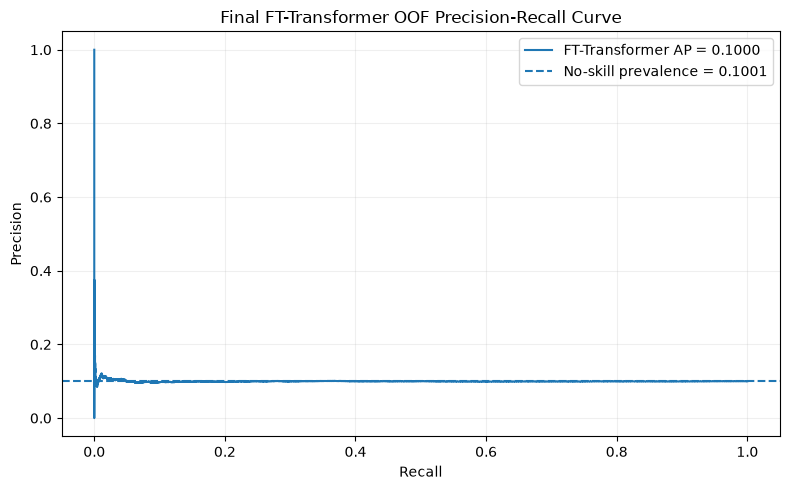

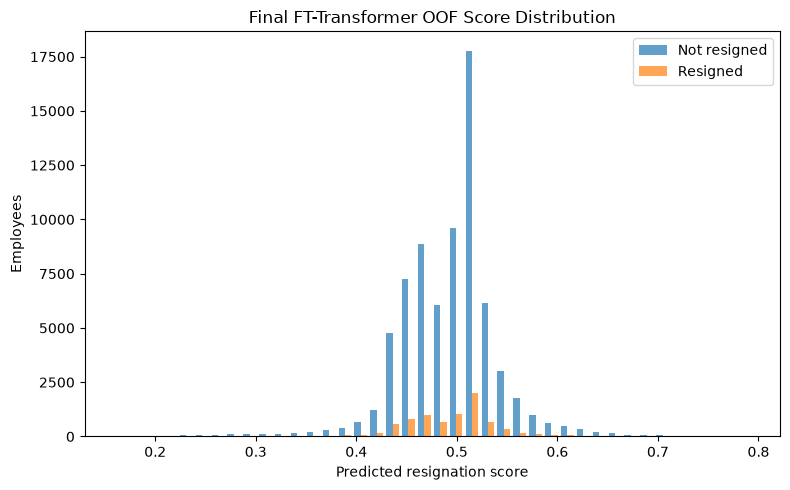

In [30]:
# -----------------------------
# 12. Final probability diagnostics and figures
# -----------------------------

probabilities = oof_predictions["y_probability"]

probability_summary = pd.DataFrame(
    {
        "Statistic": [
            "Minimum",
            "1st percentile",
            "25th percentile",
            "Median",
            "Mean",
            "75th percentile",
            "99th percentile",
            "Maximum",
        ],
        "Probability": [
            probabilities.min(),
            probabilities.quantile(0.01),
            probabilities.quantile(0.25),
            probabilities.median(),
            probabilities.mean(),
            probabilities.quantile(0.75),
            probabilities.quantile(0.99),
            probabilities.max(),
        ],
    }
)

display(probability_summary.round(6))

# FINAL_ES_DIR was selected by the training/saved-review branch.

precision, recall, _ = precision_recall_curve(
    oof_predictions["y_true"],
    oof_predictions["y_probability"],
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    recall,
    precision,
    label=f"FT-Transformer AP = {pooled_metrics['average_precision']:.4f}",
)
ax.axhline(
    prevalence,
    linestyle="--",
    label=f"No-skill prevalence = {prevalence:.4f}",
)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Final FT-Transformer OOF Precision-Recall Curve")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()

pr_curve_path = (
    FINAL_ES_DIR / "figure_01_final_ft_transformer_precision_recall_curve.png"
)
if RUN_HISTORICAL_TRAINING:
    fig.savefig(pr_curve_path, dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    [
        oof_predictions.loc[
            oof_predictions["y_true"] == 0,
            "y_probability",
        ],
        oof_predictions.loc[
            oof_predictions["y_true"] == 1,
            "y_probability",
        ],
    ],
    bins=40,
    label=["Not resigned", "Resigned"],
    alpha=0.7,
)
ax.set_xlabel("Predicted resignation score")
ax.set_ylabel("Employees")
ax.set_title("Final FT-Transformer OOF Score Distribution")
ax.legend()
fig.tight_layout()

probability_plot_path = (
    FINAL_ES_DIR / "figure_02_final_ft_transformer_oof_score_distribution.png"
)
if RUN_HISTORICAL_TRAINING:
    fig.savefig(probability_plot_path, dpi=150, bbox_inches="tight")
plt.show()


In [31]:
# -----------------------------
# 13. Save final weighted + early-stopping artifacts
# -----------------------------

# Retain the fresh destination selected by create_run_directory.

oof_path = FINAL_ES_DIR / "ft_transformer_final_oof_predictions.csv"
fold_metrics_path = FINAL_ES_DIR / "ft_transformer_final_fold_metrics.csv"
summary_path = FINAL_ES_DIR / "ft_transformer_final_summary_metrics.json"
config_path = FINAL_ES_DIR / "ft_transformer_final_configuration.json"
metadata_path = FINAL_ES_DIR / "ft_transformer_final_run_metadata.json"

if RUN_HISTORICAL_TRAINING:
    oof_predictions.to_csv(oof_path, index=False)
    fold_metrics.to_csv(fold_metrics_path, index=False)

    with open(summary_path, "w", encoding="utf-8") as file:
        json.dump(final_ft_cv_result.summary_metrics, file, indent=4, default=float)

    with open(config_path, "w", encoding="utf-8") as file:
        json.dump(final_run_params, file, indent=4, default=float)

    fold_diagnostics = final_ft_cv_result.metadata["fold_metadata"]
    assert len(fold_diagnostics) == 5
    assert all(item["adapter_metadata"]["weighting_strategy"] == "dynamic_ratio" for item in fold_diagnostics)
    run_metadata = {
        "model": model_name, "model_id": model_id,
        "experiment": "FT02_weighted_current_adapter_repetition",
        "feature_count": len(primary_model_features), "features": primary_model_features,
        "categorical_features": categorical_feature_names, "numerical_features": numerical_feature_names,
        "development_rows": len(development_data), "formal_holdout_rows_used": 0,
        "outer_cv_folds": [1, 2, 3, 4, 5], "executed_params": final_run_params,
        "candidate_id": "FT02", "elapsed_minutes": final_cv_elapsed / 60,
        "device": device_label, "torch_version": torch.__version__,
        "pooled_pr_auc": final_ft_cv_result.summary_metrics["pooled_average_precision"],
        "pooled_roc_auc": final_ft_cv_result.summary_metrics["pooled_roc_auc"],
        # Protocol fields come from the fitted fold adapters, not hardcoded claims.
        "fold_metadata": fold_diagnostics,
        "source_historical_directory": str(HISTORICAL_RESULTS_DIR.relative_to(PROJECT_ROOT)),
    }

    with open(metadata_path, "w", encoding="utf-8") as file:
        json.dump(run_metadata, file, indent=4, default=float)

    saved_files = [
        oof_path,
        fold_metrics_path,
        summary_path,
        config_path,
        metadata_path,
        pr_curve_path,
        probability_plot_path,
    ]

    assert all(path.exists() for path in saved_files)

    print("Final FT-Transformer artifacts saved:")
    for path in saved_files:
        print(" ✓", path.name, f"({path.stat().st_size:,} bytes)")

else:
    print("Saved review: historical artifacts preserved without rewriting.")


Saved review: historical artifacts preserved without rewriting.


In [32]:
# -----------------------------
# 14. Review preserved tuning and baseline evidence
# -----------------------------

TUNING_DIR = HISTORICAL_RESULTS_DIR / "tuning"
tuning_summary_path = TUNING_DIR / "final_tuning_summary.csv"

if tuning_summary_path.exists():
    tuning_summary = pd.read_csv(tuning_summary_path)
    print("Preserved tuning summary:")
    display(tuning_summary)
else:
    print(
        "Tuning summary artifact is not present in this checkout. "
        "The recorded screening decisions are documented above."
    )

print("\nHistorical artifact directories:")
for directory_name in [
    "unweighted_baseline",
    "weighted_fixed_baseline",
    "weighted_early_stopping_final",
]:
    path = RESULTS_DIR / directory_name
    print(
        f" - {directory_name}:",
        "present" if path.exists() else "not present",
    )


Preserved tuning summary:


,parameter,tested,retained_value,selection_evidence
0,learning_rate,"0.0001, 0.0003, 0.001",0.001,Best multi-seed mean inner PR-AUC: 10.66%
1,d_block,"32, 64, 128",64.000,Highest seed-42 inner PR-AUC: 10.76%
2,n_blocks,"2, 3, 4",3.000,Best multi-seed mean inner PR-AUC: 10.66%
3,ffn_d_hidden,"64, 128, 256",128.000,Best multi-seed mean inner PR-AUC: 10.66%
4,attention_n_heads,"2, 4, 8",4.000,Highest seed-42 inner PR-AUC: 10.76%
5,ffn_dropout,"0.0, 0.1, 0.2",0.100,Highest seed-42 inner PR-AUC: 10.76%



Historical artifact directories:
 - unweighted_baseline: present
 - weighted_fixed_baseline: present
 - weighted_early_stopping_final: present


In [33]:
# -----------------------------
# 15. Final integrity and consistency checks
# -----------------------------

assert len(oof_predictions) == 80_000
assert oof_predictions["Employee_ID"].nunique() == 80_000
assert set(oof_predictions["Employee_ID"]).isdisjoint(holdout_ids)
assert oof_predictions["y_probability"].between(0, 1).all()
assert oof_predictions["y_probability"].notna().all()
assert set(oof_predictions["cv_fold"].unique()) == {1, 2, 3, 4, 5}

assert len(fold_metrics) == 5
assert set(fold_metrics["fold"]) == {1, 2, 3, 4, 5}

assert np.isclose(
    pooled_metrics["average_precision"],
    final_ft_cv_result.summary_metrics["pooled_average_precision"],
)
assert np.isclose(
    pooled_metrics["roc_auc"],
    final_ft_cv_result.summary_metrics["pooled_roc_auc"],
)
assert np.isclose(
    pooled_metrics["brier_score"],
    final_ft_cv_result.summary_metrics["pooled_brier_score"],
)

expected_final_params = {
    "learning_rate": 0.001,
    "d_block": 64,
    "n_blocks": 3,
    "ffn_d_hidden": 128,
    "attention_n_heads": 4,
    "ffn_dropout": 0.1,
    "attention_dropout": 0.1,
    "residual_dropout": 0.0,
    "max_epochs": 100,
    "patience": 15,
    "validation_fraction_inner": 0.15,
    "seed": 42,
    "weighting": "dynamic_ratio",
}

for key, expected_value in expected_final_params.items():
    assert final_run_params[key] == expected_value, (
        f"{key}: expected {expected_value}, "
        f"found {final_run_params[key]}"
    )

required_final_artifacts = [
    oof_path,
    fold_metrics_path,
    summary_path,
    config_path,
    metadata_path,
]
missing_artifacts = [
    str(path)
    for path in required_final_artifacts
    if not path.exists()
]
assert not missing_artifacts, f"Missing final artifacts: {missing_artifacts}"

print("All final FT-Transformer integrity checks passed.")
print("80,000 development OOF predictions verified.")
print("Formal holdout remains untouched.")
print("Historical comparison only; group input uses the formal strict_nested results below.")


All final FT-Transformer integrity checks passed.
80,000 development OOF predictions verified.
Formal holdout remains untouched.
Historical comparison only; group input uses the formal strict_nested results below.


## Historical FT-Transformer conclusion

FT-Transformer was evaluated on all **17 approved predictors** using the frozen five-fold development protocol. The formal **20,000-row holdout was never used**.

### Preserved weighted + early-stopping result

- **Pooled PR-AUC / Average Precision:** 0.099979
- **Pooled ROC-AUC:** 0.497254
- **Pooled F1 @ 0.50:** 0.167258
- **Pooled Brier score:** 0.247413

Development resignation prevalence is approximately **10.01%**. The final PR-AUC is therefore approximately equal to the no-skill prevalence reference, while ROC-AUC is approximately 0.50.

Class weighting changed threshold behavior and increased sensitivity to the minority class, but it did not improve ranking discrimination. The weighted scores were also poorly calibrated, so they should not be interpreted directly as real-world resignation probabilities without a later calibration stage.

The final fold-level threshold behavior was unstable: one outer fold produced no positive predictions at threshold 0.50, while another predicted almost all rows as positive. This reinforces the use of ranking metrics for model comparison rather than treating the raw weighted scores as calibrated probabilities.

Controlled learning-rate and architecture screening did not identify a consistently superior FT-Transformer configuration. Further tuning was stopped to avoid excessive optimization to development-only validation noise.

**Development conclusion:** FT-Transformer does not demonstrate meaningful resignation discrimination on the approved feature set under the tested protocol.

The **weighted + inner-validation early-stopping experiment** is retained as historical evidence. The completed strict eight-candidate nested evaluation below is the current formal FT-Transformer group result. The unweighted and weighted fixed runs remain preserved as historical baselines. The formal holdout remains locked for the later pipeline-frozen final evaluation stage.


## Current evidence status

The earlier OOF predictions are preserved historical evidence. Their original implementation/protocol claims and incomplete per-fold diagnostics must remain distinct from new repetitions using the current adapter.

The formal strict nested FT run is completed: 40 inner candidate evaluations, five full outer-training winner refits and 80,000 development OOF predictions. The appended section loads its manifest-validated evidence. Pooled AP is 0.098648, mean fold AP is 0.098065 and ROC-AUC is 0.497980. Saved review is not a claim that all training has been independently repeated in this notebook session. The holdout remains locked.


# Current formal evaluation: strict eight-candidate nested development

The following cells are appended from the newer notebook and supersede the earlier workflow for group comparison. Their setup imports and loads the formal configuration independently. Historical variables are not used as formal model inputs.


# Member 1 — FT-Transformer: formal nested development evaluation

This notebook supersedes the earlier controlled-screening estimate for group comparison. The earlier workflow is retained above, with its executable code and saved outputs. Historical artifacts remain in their existing directories. The authoritative eight-candidate registry is `configs/models/ft_transformer.yaml`.

FT-Transformer combines numerical feature tokens and categorical embeddings using attention. Mixed HR predictors suit this tabular architecture, but extra capacity does not guarantee predictive signal. Numerical standardization and categorical vocabularies are fitted only on training rows. Missing/unknown categories have reserved representations; identifiers, raw hire dates and the target are excluded from predictors.

## Tuning and validation
Each frozen outer fold holds out 16,000 development records. Its 64,000 training records are split into 54,400 inner-training and 9,600 inner-validation records. FT01–FT08 vary model depth, embedding width, attention heads, learning rate, and unweighted versus fold-local positive-class weighting. Each uses inner AP early stopping (100 epoch cap, patience 15). The winning inner-AP configuration is refitted with fresh preprocessing and fresh weights on all 64,000 outer-training records for its selected epoch count. Outer validation is prediction-only. Internal candidate selection is repeated independently for all five folds: 40 candidate evaluations plus five winner refits.

A fixed seed does not guarantee identical results across hardware and library versions. Runtime versions and selection evidence are preserved. The 20,000 formal holdout records are excluded from all fitting and scoring; only their IDs are used to exclude their CSV rows. Full final model refit remains a later group decision.


In [34]:
from pathlib import Path
import sys,json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p / "configs/feature_contract.yaml").exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.models.config import load_model_config
from src.models.ft_transformer_execution import run,load_formal_ft_input
pd.set_option("display.max_columns",None)
config=load_model_config(ROOT / "configs/models/ft_transformer.yaml",strict_schema=True)
display(pd.DataFrame([dict(candidate_id=c["id"],**c["params"]) for c in config["candidates"]]))


,candidate_id,n_blocks,d_block,attention_n_heads,ffn_d_hidden,learning_rate,ffn_dropout,weighting
0,FT01,3,64,4,128,0.0010,0.1,none
1,FT02,3,64,4,128,0.0010,0.1,dynamic_ratio
2,FT03,2,64,4,128,0.0010,0.1,none
3,FT04,2,64,4,128,0.0010,0.1,dynamic_ratio
4,FT05,3,64,4,128,0.0001,0.1,none
5,FT06,3,64,4,128,0.0001,0.1,dynamic_ratio
6,FT07,3,128,8,256,0.0010,0.1,none
7,FT08,3,128,8,256,0.0010,0.1,dynamic_ratio


## Execute or load verified formal results
Set `RUN_TRAINING=True` for deliberate execution/resumption of the full experiment. The default loads its checksum-validated completed evidence without repeating training. Missing evidence raises an error rather than falling back to historical results.


In [35]:
RUN_TRAINING=False
if RUN_TRAINING:run(ROOT)
oof,fold_metrics,summary=load_formal_ft_input(ROOT)
out=ROOT / "results/models/ft_transformer/strict_nested"
selection=pd.read_csv(out / "candidate_selection.csv")
display(selection)
display(fold_metrics)
display(pd.DataFrame([summary]))

,outer_fold,candidate_id,inner_ap,selected_epoch_count,weighting,fit_time_seconds
0,1,FT01,0.106393,16,none,81.102429
1,1,FT02,0.108877,16,dynamic_ratio,74.378143
2,1,FT03,0.106501,32,none,82.824045
3,1,FT04,0.107140,28,dynamic_ratio,72.597910
4,1,FT05,0.107985,2,none,40.084606
5,1,FT06,0.107047,3,dynamic_ratio,41.942914
6,1,FT07,0.105861,22,none,161.735435
7,1,FT08,0.106288,15,dynamic_ratio,142.627056
8,2,FT01,0.101053,16,none,79.015480
9,2,FT02,0.103633,25,dynamic_ratio,103.099105


,fold,fit_time_seconds,predict_time_seconds,selected_candidate,selected_epoch_count,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate
0,1,745.100103,0.196453,FT02,16,0.096581,0.493389,0.083598,0.049344,0.062058,0.494601,0.850750,0.242686,13533,866,1522,79,945,0.059062
1,2,684.240823,0.199332,FT05,1,0.101352,0.505661,0.000000,0.000000,0.000000,0.500000,0.899937,0.090118,14399,0,1601,0,0,0.000000
2,3,633.130631,0.192161,FT02,17,0.095313,0.484555,0.095386,0.480025,0.159147,0.486748,0.492125,0.252314,7105,7293,833,769,8062,0.503875
3,4,693.827556,0.145339,FT03,36,0.100386,0.495808,0.000000,0.000000,0.000000,0.500000,0.899875,0.090162,14398,0,1602,0,0,0.000000
4,5,687.235968,0.208957,FT01,30,0.096695,0.490546,0.000000,0.000000,0.000000,0.500000,0.899875,0.090150,14398,0,1602,0,0,0.000000


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate,model_name,cv_mean_ap,cv_std_ap,cv_mean_roc_auc,total_fit_time_seconds,total_predict_time_seconds,development_rows,outer_folds,candidate_evaluations,formal_holdout_used,final_model_frozen,protocol
0,0.098648,0.49798,0.094149,0.105894,0.099677,0.496281,0.808512,0.153086,63833,8159,7160,848,9007,0.112587,FT-Transformer,0.098065,0.002638,0.493992,3443.535081,0.942243,80000,5,40,False,False,strict_nested_eight_candidate_selection


## Evaluation and comparison across candidate varieties
Average Precision is primary at ~10% positive prevalence; the no-skill reference is ~.1001. ROC-AUC compares ranking across both classes (chance .5); Brier measures probability error (lower is better). Recall, precision, F1 and balanced accuracy describe a clearly fixed .50 threshold. Fold standard deviations describe variability, not confidence intervals. Candidate inner scores support within-fold selection; their means below are descriptive, not unbiased outer performance estimates for each fixed candidate. The outer scores evaluate the nested selection procedure.


,mean_inner_ap,sd_inner_ap,mean_selected_epochs
candidate_id,,,
FT01,0.103876,0.002559,17.4
FT02,0.104741,0.003397,16.6
FT03,0.104297,0.002394,22.4
FT04,0.102374,0.002847,16.8
FT05,0.103325,0.003050,1.8
FT06,0.102718,0.002874,2.8
FT07,0.103019,0.003253,14.8
FT08,0.102331,0.002848,8.0


,fold,selected_candidate,selected_epoch_count,average_precision,roc_auc,recall,f1
0,1,FT02,16,0.096581,0.493389,0.049344,0.062058
1,2,FT05,1,0.101352,0.505661,0.000000,0.000000
2,3,FT02,17,0.095313,0.484555,0.480025,0.159147
3,4,FT03,36,0.100386,0.495808,0.000000,0.000000
4,5,FT01,30,0.096695,0.490546,0.000000,0.000000


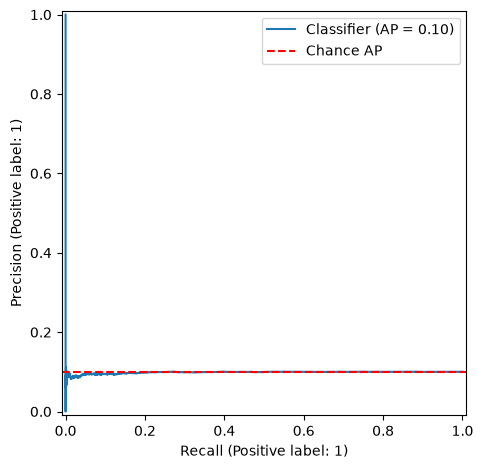

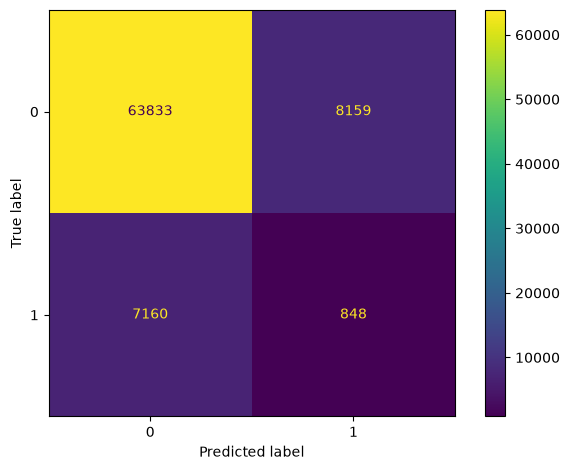

Mean fold AP (separate from pooled group ranking): 0.09806541461164146 Pooled AP: 0.09864796531239689 ROC-AUC: 0.4979796229231931


In [36]:
display(selection.groupby("candidate_id").agg(mean_inner_ap=("inner_ap","mean"),sd_inner_ap=("inner_ap","std"),mean_selected_epochs=("selected_epoch_count","mean")))
display(fold_metrics[["fold","selected_candidate","selected_epoch_count","average_precision","roc_auc","recall","f1"]])
from sklearn.metrics import PrecisionRecallDisplay,ConfusionMatrixDisplay
PrecisionRecallDisplay.from_predictions(oof.y_true,oof.y_probability)
plt.axhline(oof.y_true.mean(),linestyle="--",color="red",label="Chance AP");plt.legend();plt.tight_layout();plt.show()
ConfusionMatrixDisplay.from_predictions(oof.y_true,oof.y_pred_0_5)
plt.tight_layout();plt.show()
print("Mean fold AP (separate from pooled group ranking):",summary["cv_mean_ap"],"Pooled AP:",summary["average_precision"],"ROC-AUC:",summary["roc_auc"])

## Limitations and group handoff
Interpret the numerical AP against chance and fold variability; do not equate a small ranking lead with a useful retention tool. Weighted loss may change probability calibration substantially, so calibration and threshold choices require separate development-only analysis. Attention is not a causal explanation. A bounded eight-candidate search is not a global optimum guarantee, and one inner split adds selection variance.

The formal group input is `results/models/ft_transformer/strict_nested/oof_predictions.csv`. The loader validates config/adapter/split provenance and artifact checksums, accepting LF and CRLF representations. Group comparison must use the same frozen development folds and pooled AP as its declared primary ranking metric, with mean fold AP reported separately. No model is automatically selected for deployment or final holdout merely because it ranks first.
